# Прогнозирование продаж офлайн-ритейлера классическими методами

**Курс:** Прикладной анализ временных рядов (ИТМО). **Практическое задание №1.**

Задача: по дневным продажам 15 товаров одного магазина построить прогноз спроса
на **неделю (7 дней)**, **месяц (30 дней)** и **квартал (90 дней)** с помощью
классических моделей (лекции 2-5), оценить качество и сравнить подходы.

Выбран магазин **`STORE_2`** - самый крупный по обороту (в среднем ≈420 шт. в день).

Весь код вынесен в пакет `src/sales_forecast`. В ноутбуке только вызовы методов
класса `SalesForecaster`, визуализации и комментарии.


In [1]:
import logging
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))

from sales_forecast import HoltWintersModel, RegressionModel, SalesForecaster  # noqa: E402

warnings.filterwarnings("ignore")
logging.getLogger("sales_forecast").setLevel(logging.WARNING)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})

DATA_DIR = Path.cwd().parent / "data"
STORE = "STORE_2"

## 1. Описание реализованного класса

Пакет `sales_forecast` состоит из четырех модулей, собранных фасадом `SalesForecaster`:

| Модуль | Назначение |
|---|---|
| `data.py` | загрузка трех CSV, валидация, сборка `StoreDataset` (wide-матрица продаж с `DatetimeIndex(freq='D')`, календарные экзогенные признаки, дневные цены), функции предобработки `trim_leading_zeros`, `impute_closed_days` |
| `models.py` | модели за единым интерфейсом `fit(y, exog)`, `predict(horizon, exog)`: `SeasonalNaiveModel`, `HoltWintersModel`, `SarimaModel` (пошаговый подбор порядка по AIC), `RegressionModel` (тренд + Фурье + экзогенные), обертка `Log1pModel` |
| `metrics.py` | MAE, RMSE, WAPE, MASE - по одному ряду и в пуле по всем товарам |
| `plotting.py` | графики рядов, прогнозов и метрик |
| `forecaster.py` | класс **`SalesForecaster`** - весь пайплайн |

### Основные методы `SalesForecaster`

| Метод | Что делает |
|---|---|
| `load_data()` | читает CSV, строит датасет магазина (предобработка формата) |
| `describe_items()` | сводка по товарам: среднее, доля нулей, дата первой продажи, цена |
| `decompose(item)` | STL-разложение ряда (EDA) |
| `split(train_end)` | train и test: тест - `test_size` (= 90) дней после `train_end` |
| `fit(train_end=None)` | предобработка каждого ряда, обучение всех моделей на всех товарах, прогноз на 90 дней |
| `predict(horizon)` | прогнозы `{модель: DataFrame(даты x товары)}` на 7, 30, 90 дней |
| `evaluate()` | метрики по каждому (модель, товар, горизонт) |
| `evaluate_total()`, `summary(metric)` | метрики в пуле по всем товарам, сводная таблица модель x горизонт |
| `best_model(metric, horizon)` | лучшая модель по метрике |
| `backtest(n_folds)` | rolling-origin валидация с неперекрывающимися тестовыми окнами |
| `plot_items()`, `plot_forecast()`, `plot_total_metrics()`, `plot_item_metrics()` | визуализации |
| `selected_orders()`, `forecast_table()` | выбранные порядки SARIMA, прогнозы всех моделей по товару таблицей |

Предобработка внутри `fit` для каждого товара: (1) интерполяция продаж в дни, когда магазин закрыт
(25 декабря - нулевые продажи все годы), (2) отсечение ведущих нулей у товаров, появившихся позже
начала данных, (3) опционально ограничение истории последними `train_window` днями и `log1p`. Пост-обработка прогноза: отсечение отрицательных значений и
принудительный ноль в закрытые дни.


## 2. Загрузка данных и первичный анализ

In [2]:
forecaster = SalesForecaster(STORE, data_dir=DATA_DIR)
dataset = forecaster.load_data()
print(f"Период: {dataset.sales.index[0].date()} - {dataset.sales.index[-1].date()}, "
      f"{len(dataset.sales)} дней, {len(dataset.items)} товаров")
dataset.sales.head()


Период: 2011-01-29 — 2016-01-21, 1819 дней, 15 товаров


,STORE_2_043,STORE_2_054,STORE_2_085,STORE_2_090,STORE_2_252,STORE_2_325,STORE_2_376,STORE_2_391,STORE_2_524,STORE_2_555,STORE_2_586,STORE_2_587,STORE_2_681,STORE_2_714,STORE_2_716
date,,,,,,,,,,,,,,,
2011-01-29,6.0,6.0,3.0,108.0,39.0,0.0,7.0,0.0,0.0,18.0,56.0,0.0,14.0,18.0,0.0
2011-01-30,0.0,12.0,8.0,132.0,38.0,0.0,9.0,0.0,1.0,38.0,55.0,0.0,10.0,17.0,0.0
2011-01-31,0.0,5.0,0.0,102.0,18.0,0.0,8.0,0.0,0.0,14.0,45.0,0.0,9.0,10.0,0.0
2011-02-01,1.0,10.0,3.0,120.0,37.0,0.0,16.0,0.0,0.0,22.0,57.0,84.0,5.0,15.0,0.0
2011-02-02,0.0,19.0,0.0,106.0,40.0,0.0,8.0,0.0,0.0,31.0,54.0,73.0,6.0,7.0,0.0


In [3]:
# Календарные признаки (общие для всех товаров) и дневные цены (по товарам)
display(dataset.exog.describe().T[["mean", "max"]].rename(columns={"mean": "доля дней"}))
dataset.prices.iloc[:, :6].head(3)

,доля дней,max
event_cultural,0.019241,1.0
event_national,0.027488,1.0
event_religious,0.027488,1.0
event_sporting,0.008246,1.0
is_closed,0.002749,1.0
cashback,0.329852,1.0


,STORE_2_043,STORE_2_054,STORE_2_085,STORE_2_090,STORE_2_252,STORE_2_325
date,,,,,,
2011-01-29,2.88,2.28,1.0,1.25,1.48,1.0
2011-01-30,2.88,2.28,1.0,1.25,1.48,1.0
2011-01-31,2.88,2.28,1.0,1.25,1.48,1.0


In [4]:
forecaster.describe_items().round(2)

,mean,std,zero_share,max,first_sale,mean_price
STORE_2_090,132.09,110.96,0.20,763.0,2011-01-29,1.33
STORE_2_586,70.57,17.89,0.00,151.0,2011-01-29,1.59
STORE_2_252,42.74,16.10,0.00,138.0,2011-01-29,1.52
STORE_2_587,36.80,30.38,0.10,154.0,2011-02-01,2.51
STORE_2_555,30.99,9.62,0.00,76.0,2011-01-29,1.59
STORE_2_681,28.45,25.02,0.08,207.0,2011-01-29,1.10
STORE_2_714,27.06,11.25,0.00,84.0,2011-01-29,1.52
STORE_2_376,19.07,17.18,0.09,166.0,2011-01-29,1.00
STORE_2_524,12.07,11.65,0.19,85.0,2011-01-30,0.99
STORE_2_325,7.65,6.16,0.15,43.0,2011-08-13,1.15


Товары очень разнородны: от `STORE_2_090` (≈130 шт. в день, но 20 % нулевых дней) до
`STORE_2_043`, `STORE_2_391`, `STORE_2_716` (меньше 1 шт. в день, 60-73 % нулей - прерывистый спрос).
Три товара (`325`, `391`, `716`) появились в продаже позже начала наблюдений - до первой цены продаж нет,
этот период не является спросом и отрезается при обучении.


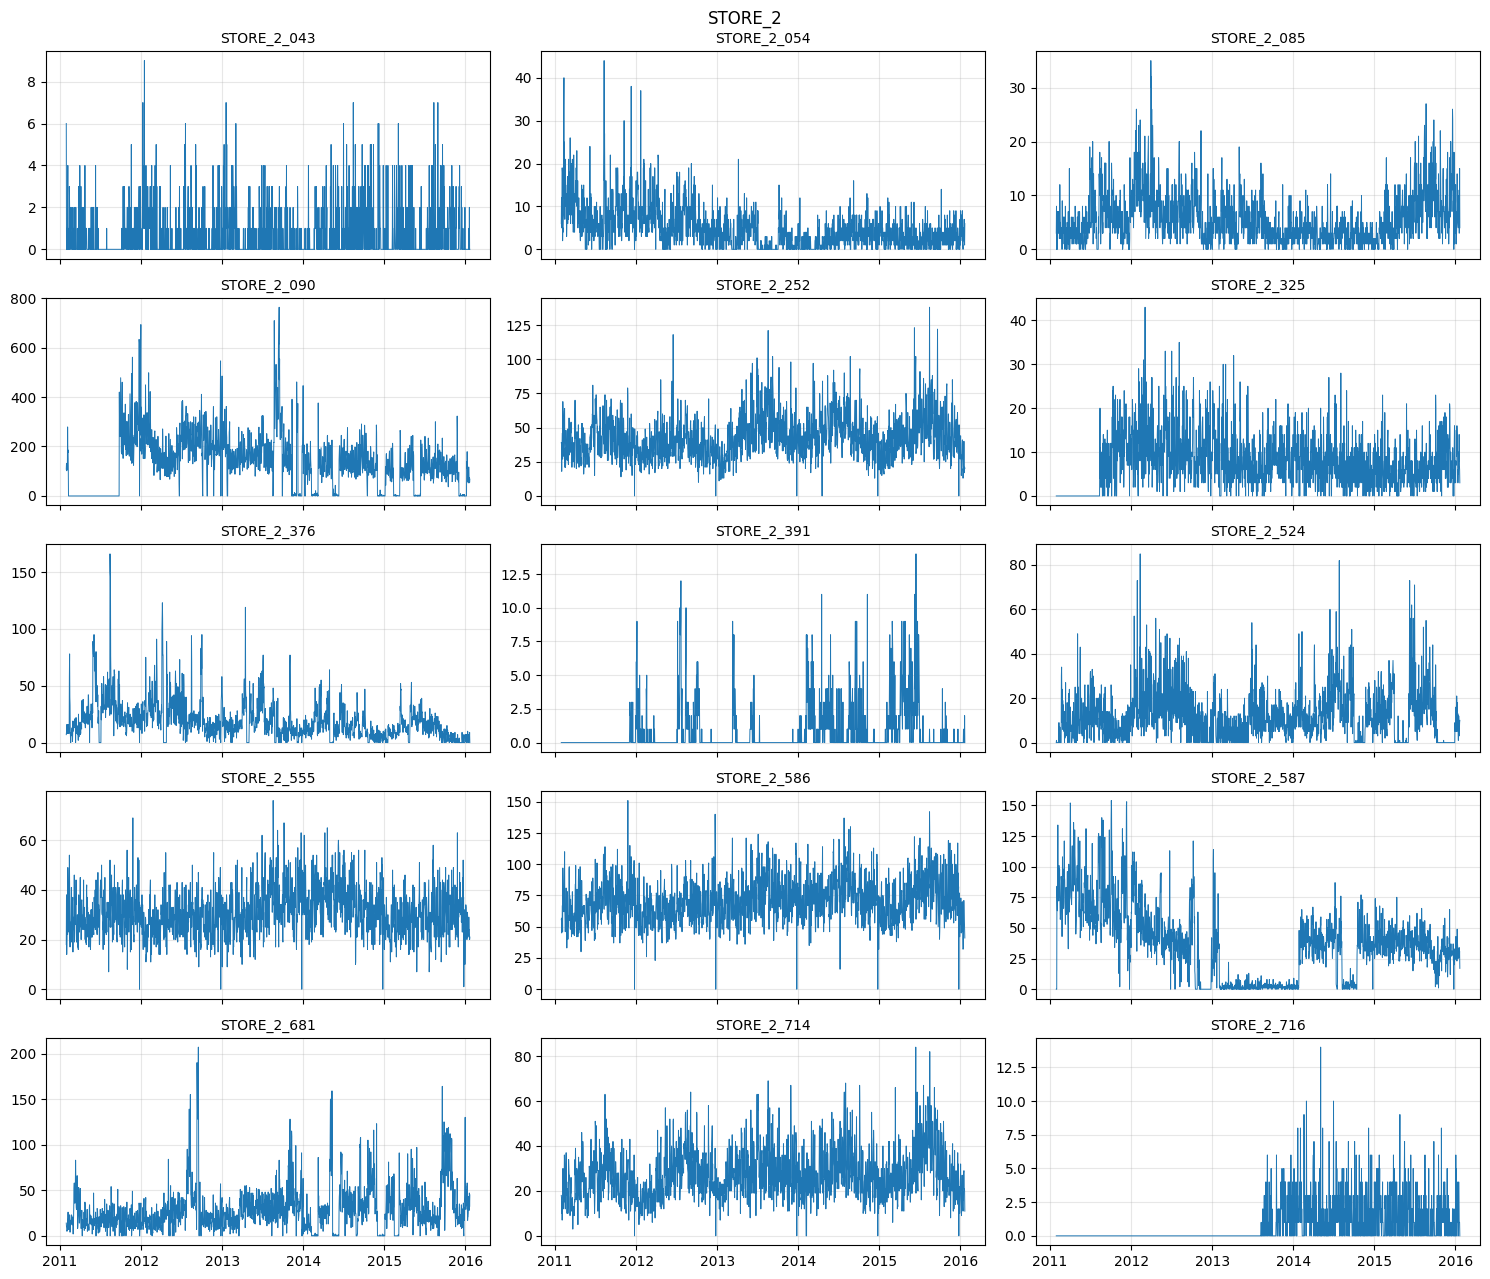

In [5]:
forecaster.plot_items();

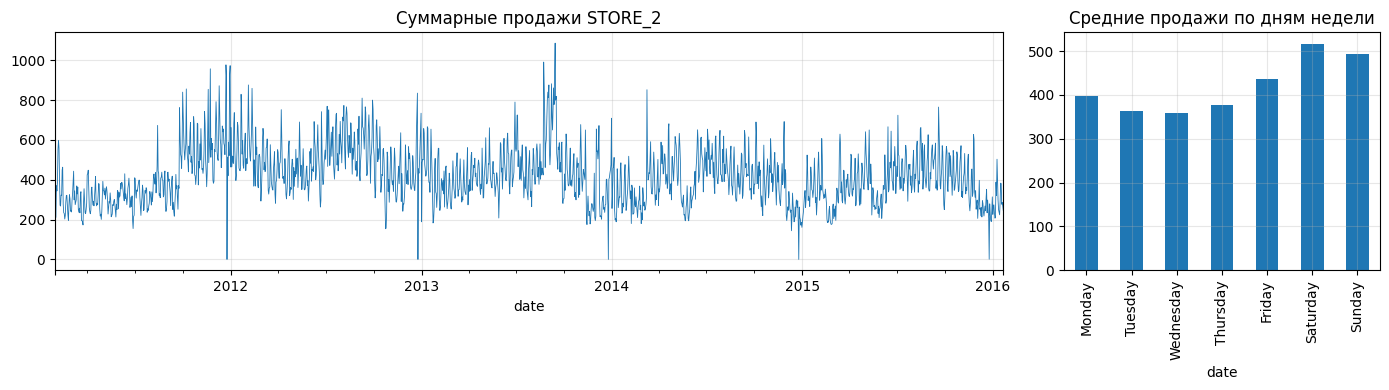

In [6]:
# Суммарные продажи магазина и недельная сезонность
total = dataset.sales.sum(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 1]})
total.plot(ax=axes[0], linewidth=0.6, title="Суммарные продажи STORE_2")
total.groupby(total.index.day_name()).mean().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
).plot.bar(ax=axes[1], title="Средние продажи по дням недели")
plt.tight_layout()

Видна выраженная **недельная сезонность** (пик в субботу-воскресенье, провал в середине недели),
слабый тренд и регулярные провалы 25 декабря. Посмотрим STL-разложение двух контрастных товаров:
стабильного `STORE_2_586` и самого крупного `STORE_2_090`.


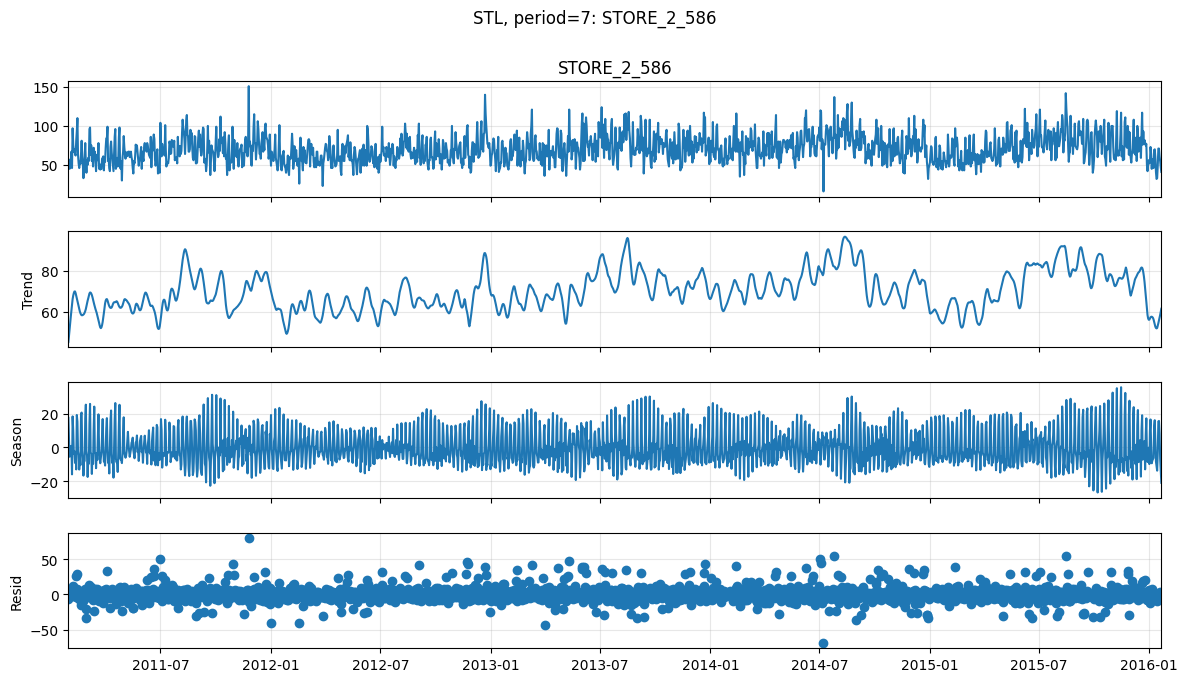

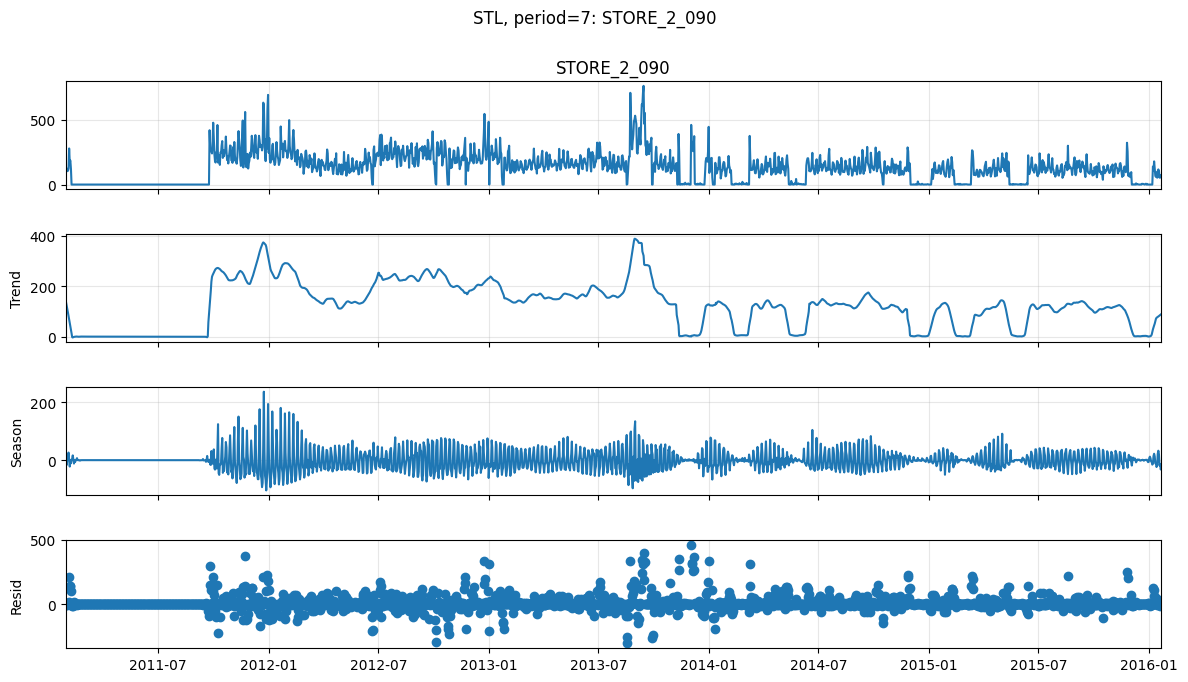

In [7]:
for item in ["STORE_2_586", "STORE_2_090"]:
    fig = forecaster.decompose(item).plot()
    fig.set_size_inches(12, 7)
    fig.suptitle(f"STL, period=7: {item}", y=1.01)

У `STORE_2_090` помимо недельной сезонности есть **годовой паттерн**: каждый декабрь продажи
падают почти до нуля на ~месяц (товар сезонно отсутствует), в 2011 году был восьмимесячный период
без продаж, а в остальное время ряд сильно волатилен. Это важно, потому что тестовый квартал (24.10.2015 - 21.01.2016) включает декабрь, и
именно этот товар дает наибольший вклад в суммарную ошибку.


## 3. Обучение моделей

Тестовая выборка - **последние 90 дней** (24.10.2015 - 21.01.2016), все до нее - обучение.
Каждая модель обучается отдельно на каждом из 15 товаров и строит прогноз на 90 дней. Оценка на
неделю, месяц, квартал - первые 7, 30, 90 дней этого прогноза.

Модели (все из лекций 2-5):

1. **Seasonal Naive** (лаг 7) - повторение последней недели. Базовая линия: любая модель, которая ее не
   обгоняет, бесполезна. Также задает масштаб для MASE.
2. **Holt-Winters** - аддитивное экспоненциальное сглаживание с демпфированным трендом и недельной
   сезонностью. Адаптивная локальная модель уровня, тренда, сезона.
3. **SARIMA(p,d,q)(P,D,Q)₇** - стохастическая модель. Порядок подбирается по AIC пошагово
   (сначала сезонная часть при (p,q)=(1,1), затем несезонная), `d` - по тесту KPSS, `D=1`.
4. **Регрессия** на детерминированные компоненты (линейный тренд + гармоники Фурье недельного периода)
   и **экзогенные признаки** (цена товара, типы праздников, флаг закрытого дня, кэшбэк) - подход из
   семинара 1 "тренд + сезонные dummy". Единственная модель, использующая дополнительные таблицы.


In [8]:
%%time
forecaster.fit();

CPU times: user 2min 6s, sys: 1.77 s, total: 2min 8s
Wall time: 2min 9s


In [9]:
forecaster.selected_orders().set_index("item")

,model,order,seasonal_order
item,,,
STORE_2_043,sarima,"(2, 0, 2)","(1, 1, 1)"
STORE_2_054,sarima,"(2, 0, 2)","(0, 1, 1)"
STORE_2_085,sarima,"(2, 0, 2)","(0, 1, 1)"
STORE_2_090,sarima,"(2, 0, 2)","(0, 1, 1)"
STORE_2_252,sarima,"(2, 0, 2)","(0, 1, 1)"
STORE_2_325,sarima,"(2, 0, 2)","(0, 1, 1)"
STORE_2_376,sarima,"(2, 0, 2)","(0, 1, 1)"
STORE_2_391,sarima,"(1, 0, 2)","(0, 1, 1)"
STORE_2_524,sarima,"(1, 0, 2)","(0, 1, 1)"


AIC почти для всех товаров выбирает `SARIMA(2,0,2)(0,1,1)₇`: сезонное дифференцирование плюс
сезонный MA-член - это стохастический аналог сезонного экспоненциального сглаживания, а `d = 0`
(по KPSS) говорит, что после снятия недельной сезонности ряды стационарны по уровню. Несезонная
часть упирается в границу сетки (2, 2) - на 1700 наблюдениях AIC охотно платит за дополнительные
параметры. Сетку намеренно не расширяем, чтобы не переобучаться и не раздувать время подбора.


## 4. Результаты на отложенной выборке

### Метрики

* **MAE** - средняя абсолютная ошибка в штуках, интерпретируема для бизнеса.
* **RMSE** - сильнее штрафует крупные промахи (важно для пиков спроса).
* **WAPE** = Σ|ошибка| / Σ|факт| - относительная ошибка, корректно определена при нулевых продажах
  (в отличие от MAPE, которая делит на ноль. У нас до 73 % нулевых дней по ряду).
* **MASE** - MAE, нормированная на MAE сезонного наивного прогноза внутри обучающей выборки:
  значение < 1 означает, что модель лучше наивного повторения прошлой недели. Метрика сравнима между
  товарами разного масштаба.

В пуле по всем товарам WAPE и MASE считаются по суммам ошибок, поэтому крупные товары весят больше -
это соответствует смыслу "общая ошибка относительно общего объема продаж".


In [10]:
for metric in ["wape", "mase", "mae", "rmse"]:
    print(metric.upper())
    display(forecaster.summary(metric).round(3))

WAPE


horizon,week,month,quarter
model,,,
holt_winters,0.204,0.305,0.577
regression,0.295,0.332,0.532
sarima,0.164,0.250,0.460
seasonal_naive,0.250,0.343,0.621


MASE


horizon,week,month,quarter
model,,,
holt_winters,0.535,0.739,1.127
regression,0.775,0.805,1.037
sarima,0.429,0.606,0.897
seasonal_naive,0.656,0.831,1.213


MAE


horizon,week,month,quarter
model,,,
holt_winters,5.939,8.201,12.515
regression,8.610,8.935,11.519
sarima,4.766,6.731,9.958
seasonal_naive,7.286,9.222,13.466


RMSE


horizon,week,month,quarter
model,,,
holt_winters,10.018,16.294,27.673
regression,13.446,14.014,22.525
sarima,6.992,9.900,21.657
seasonal_naive,11.086,17.554,27.753


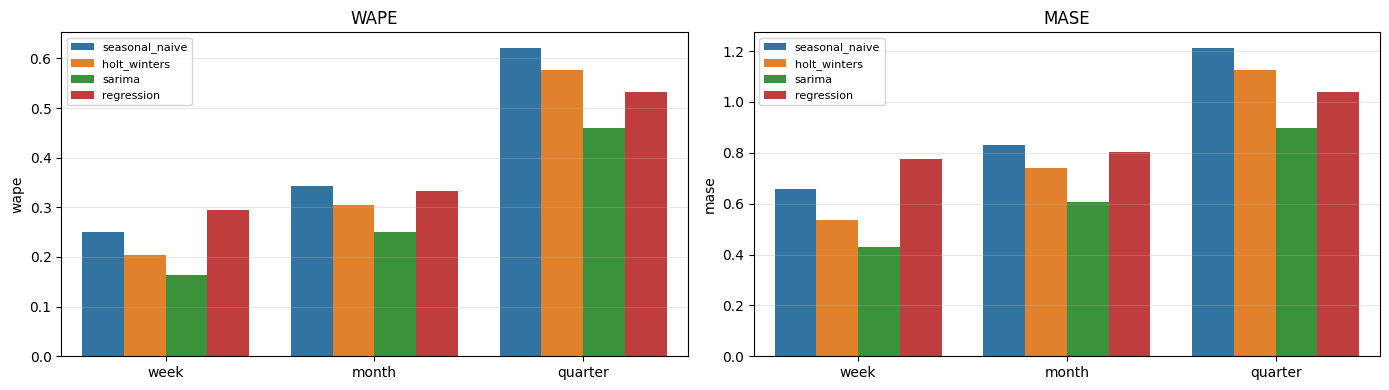

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
forecaster.plot_total_metrics("wape", ax=axes[0])
forecaster.plot_total_metrics("mase", ax=axes[1])
plt.tight_layout()

**SARIMA лучше всех на всех трех горизонтах** по всем четырем метрикам. Holt-Winters - вторая на
неделе и месяце, регрессия - вторая на квартале, сезонный наивный прогноз - худший везде.
Ошибка закономерно растет с горизонтом: WAPE SARIMA 16 %, 25 %, 46 %. На квартале только SARIMA
сохраняет MASE < 1, то есть остается точнее наивного повторения недели.

Посмотрим, как ошибка распределена по товарам.


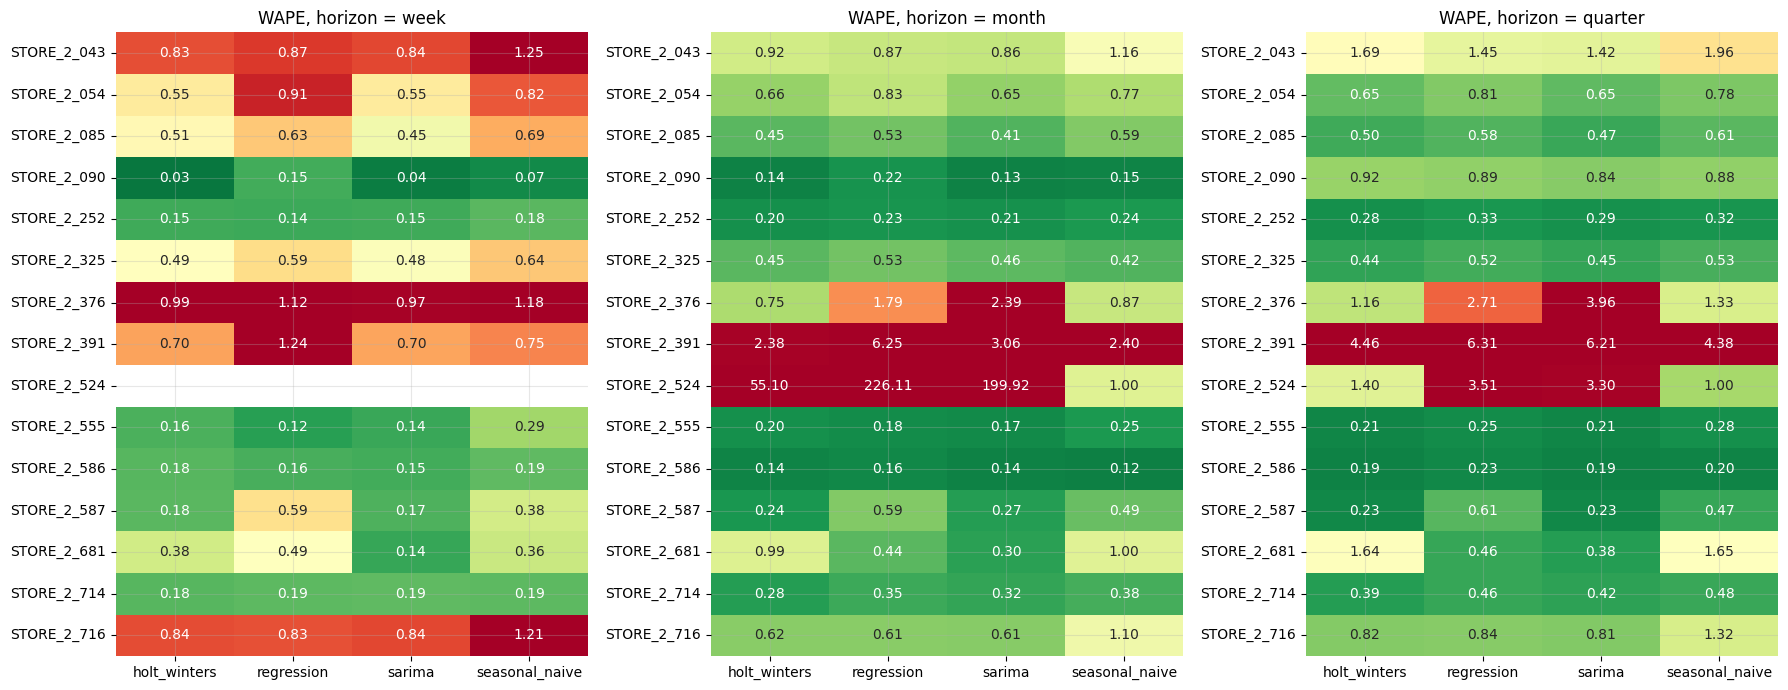

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, horizon in zip(axes, ["week", "month", "quarter"]):
    forecaster.plot_item_metrics("wape", horizon, ax=ax)
plt.tight_layout()

Качество сильно зависит от характера ряда:

* **стабильные крупные товары** (`586`, `555`, `252`, `714`, `090` на неделе) - WAPE 3-30 %.
* **прерывистые** (`043`, `391`, `716`, менее 1 шт. в день) - WAPE 0.6-6: точечный прогноз для
  таких рядов в принципе плохо определен, нужны специальные методы (Кростон и т. п.).
* `STORE_2_524` в тестовом периоде практически **исчез из продажи** (нулевые продажи в первой
  неделе - WAPE не определен, затем ~2.5 месяца без продаж): структурный разрыв, который по
  истории ряда предсказать нельзя. Отсюда аномальные значения во всех моделях.


### Визуализация прогнозов

Для каждого горизонта несколько характерных товаров: стабильный крупный (`586`), крупный с
годовым окном (`090`), товар со сдвигом уровня (`681`) и прерывистый (`043`).


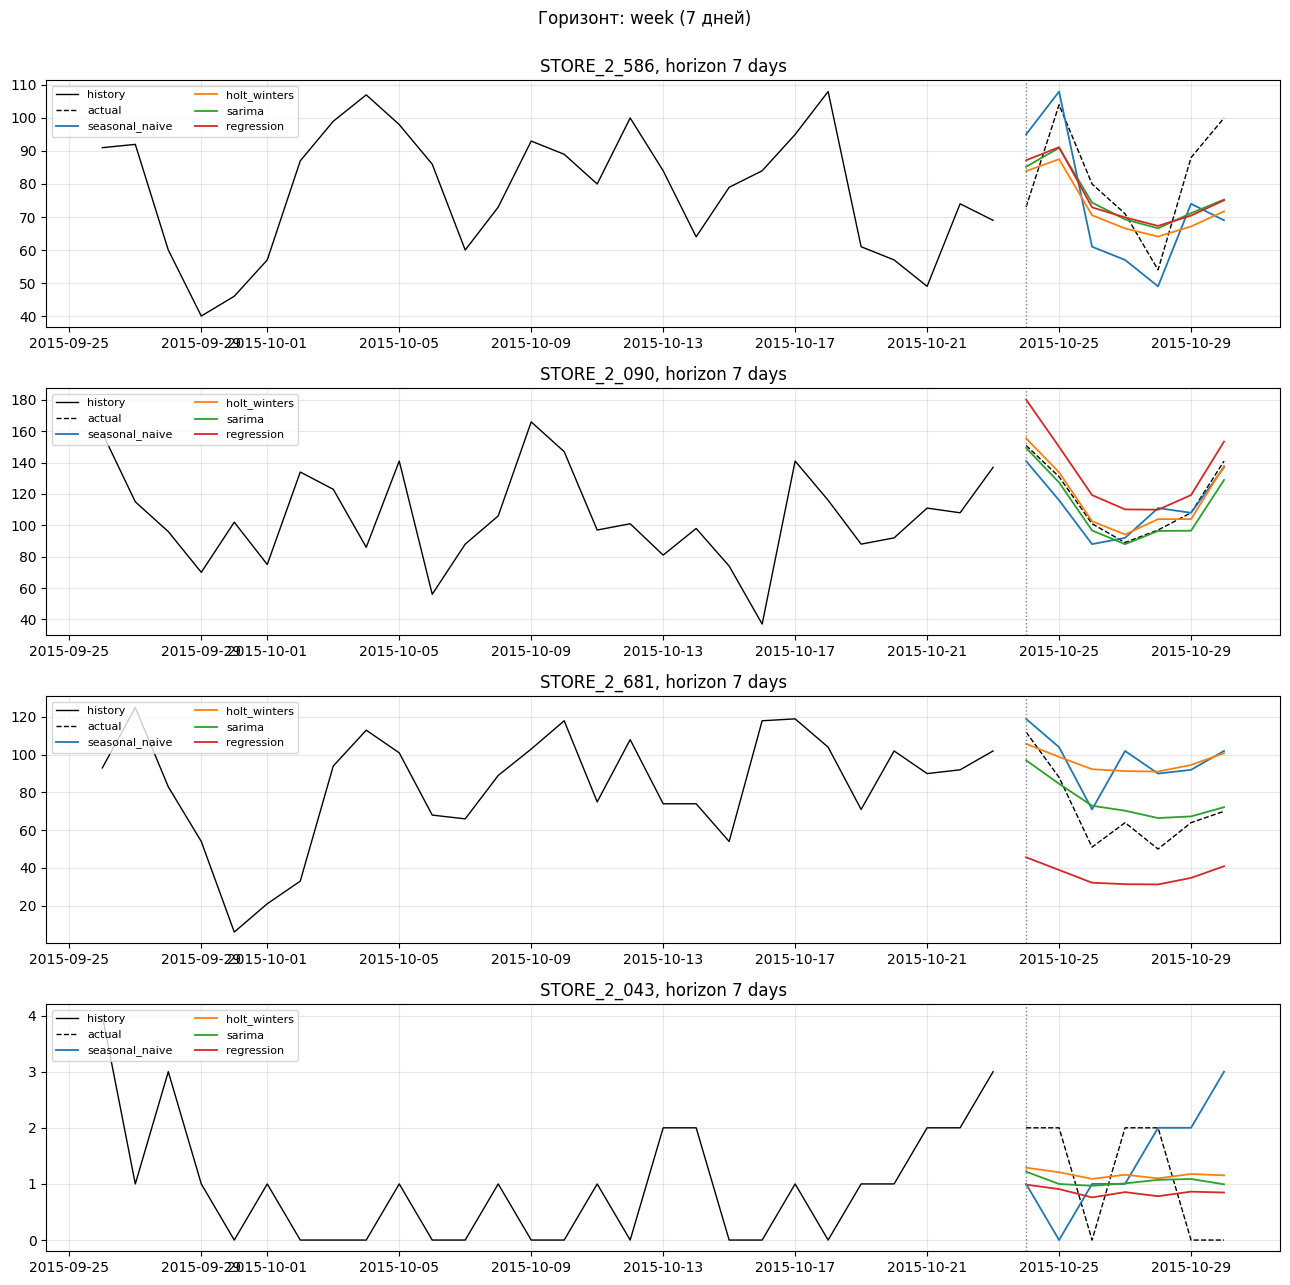

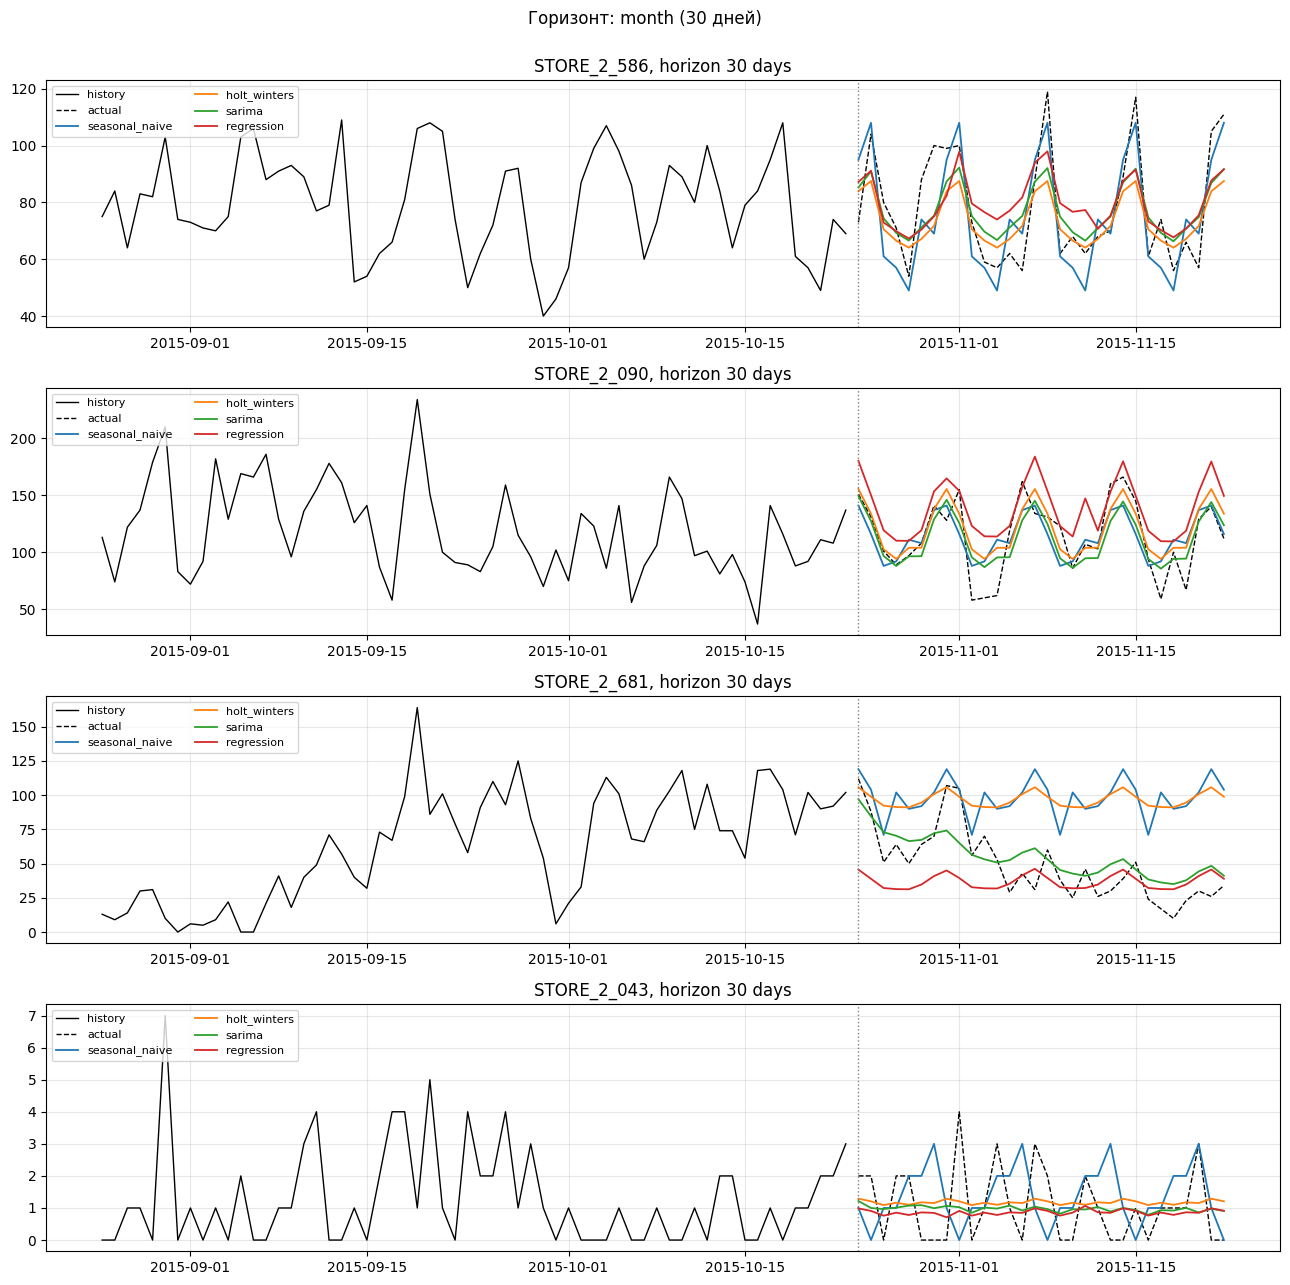

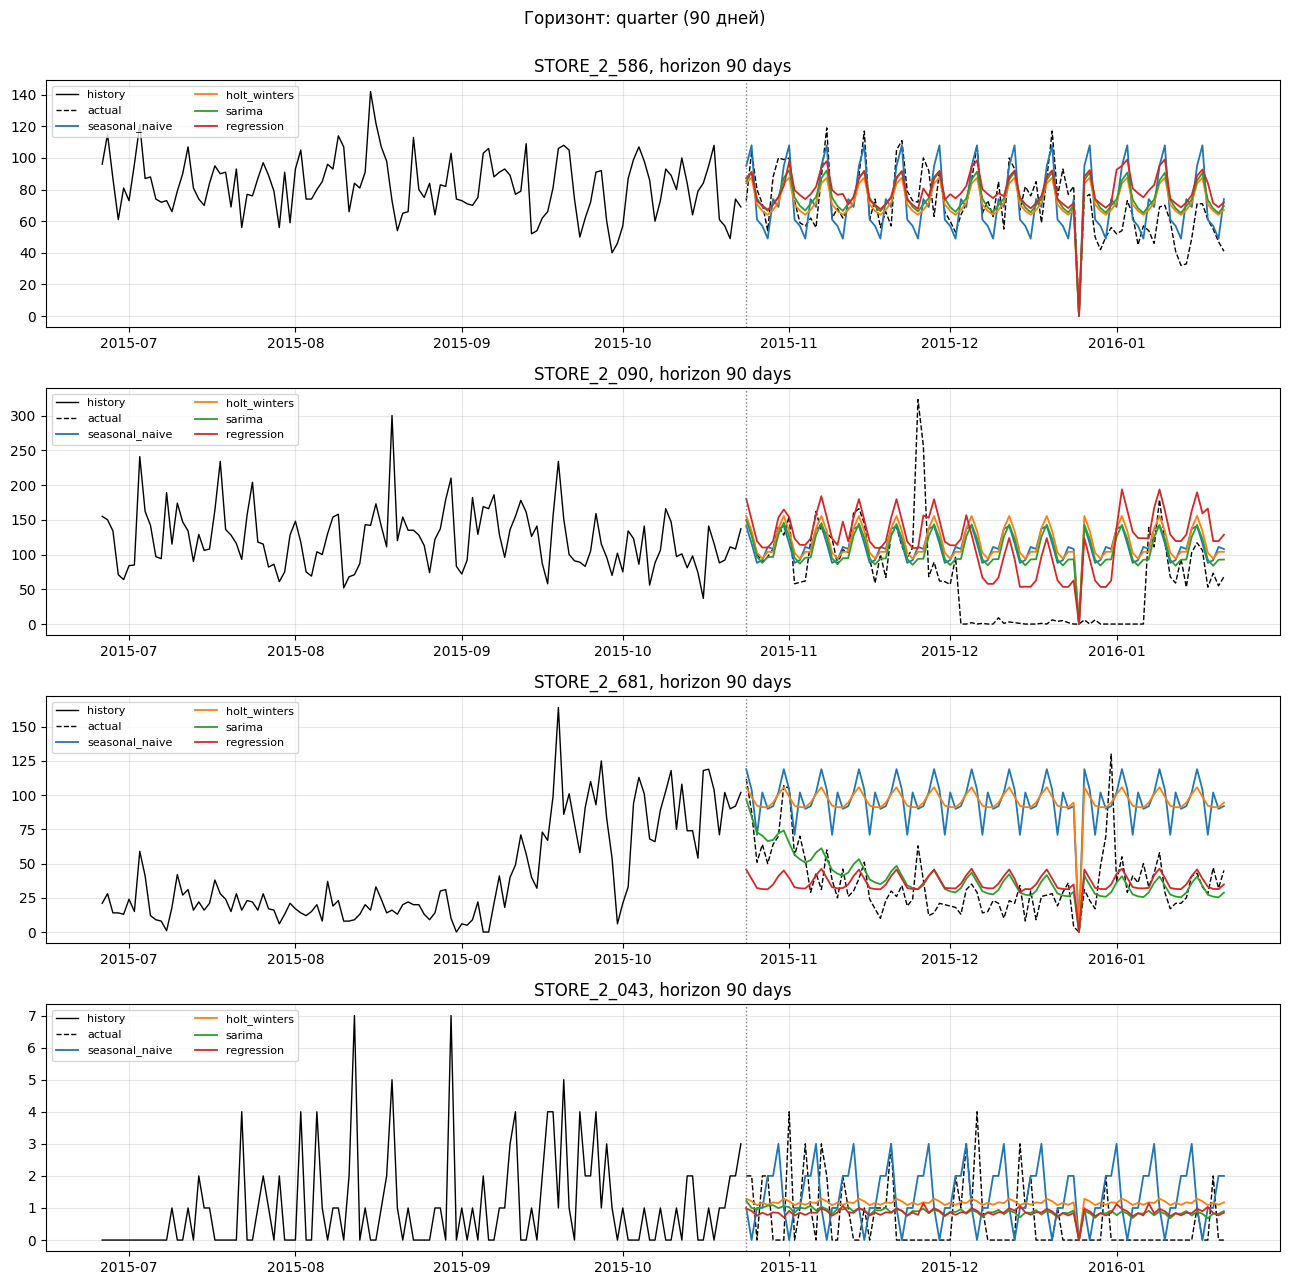

In [13]:
SHOW_ITEMS = ["STORE_2_586", "STORE_2_090", "STORE_2_681", "STORE_2_043"]
for horizon, history in [("week", 28), ("month", 60), ("quarter", 120)]:
    fig, axes = plt.subplots(len(SHOW_ITEMS), 1, figsize=(13, 3.2 * len(SHOW_ITEMS)))
    for ax, item in zip(axes, SHOW_ITEMS):
        forecaster.plot_forecast(item, horizon, history_days=history, ax=ax)
    fig.suptitle(f"Горизонт: {horizon} ({forecaster.horizons[horizon]} дней)", y=1.0)
    plt.tight_layout()

Что видно на графиках:

* `586` - все модели воспроизводят недельный профиль. SARIMA и Holt-Winters ближе к факту по уровню.
* `090` - в декабре факт уходит в ноль на месяц (сезонное отсутствие товара). Ни одна недельная
  модель этого не знает, отсюда основная доля квартальной ошибки. Провал всех моделей 25 декабря -
  результат пост-обработки (известный закрытый день).
* `681` - в сентябре 2015 цена снизилась с 1.25 до 1.00, продажи выросли с ~18 до ~90 шт. в день, а в
  тесте всплеск затух. Holt-Winters и наивный прогноз экстраполируют последний (пиковый) уровень,
  а регрессия с глобальным трендом и стационарная AR-часть SARIMA возвращаются к долгосрочному
  среднему. Здесь это оказалось правильным.
* `043` - прерывистый спрос: сглаживающие модели дают "ожидаемое" значение около 1, наивный прогноз
  повторяет случайные всплески последней недели и потому проигрывает.


In [14]:
# Прогнозы на неделю для самого стабильного товара в табличном виде
forecaster.forecast_table("STORE_2_586", "week").round(1)

,actual,seasonal_naive,holt_winters,sarima,regression
date,,,,,
2015-10-24,73.0,95.0,83.9,85.2,87.2
2015-10-25,104.0,108.0,87.5,90.9,91.1
2015-10-26,80.0,61.0,70.5,74.4,72.9
2015-10-27,71.0,57.0,66.5,69.3,69.9
2015-10-28,54.0,49.0,64.1,66.6,67.3
2015-10-29,88.0,74.0,67.1,71.2,70.4
2015-10-30,100.0,69.0,71.7,75.3,75.1


## 5. Эксперименты с предобработкой

### 5.1 Логарифмирование целевой переменной

Для рядов, у которых дисперсия растет с уровнем, аддитивная модель на `log1p(y)` эквивалентна
мультипликативной на исходной шкале. Проверим на Holt-Winters и регрессии.


In [15]:
%%time
log_forecaster = SalesForecaster(STORE, data_dir=DATA_DIR,
                                 models=["holt_winters", "regression"], log_transform=True)
log_forecaster.load_data()
log_forecaster.fit()

comparison = pd.concat(
    {"исходная шкала": forecaster.summary("wape").loc[["holt_winters", "regression"]],
     "log1p": log_forecaster.summary("wape")},
    names=["предобработка", "model"],
)
comparison.round(3)

CPU times: user 2.8 s, sys: 26.4 ms, total: 2.83 s
Wall time: 2.85 s


horizon                       week  month  quarter
предобработка  model                              
исходная шкала holt_winters  0.204  0.305    0.577
               regression    0.295  0.332    0.532
log1p          holt_winters  0.216  0.318    0.595
               regression    0.496  0.524    0.728

In [16]:
log_forecaster.evaluate().query("horizon == 'quarter'").set_index("item")[["model", "wape"]] \
    .pivot(columns="model", values="wape").round(2)

model,holt_winters,regression
item,,
STORE_2_043,1.47,1.26
STORE_2_054,0.64,0.75
STORE_2_085,0.54,0.67
STORE_2_090,1.06,1.93
STORE_2_252,0.28,0.30
STORE_2_325,0.46,0.56
STORE_2_376,1.02,2.04
STORE_2_391,3.94,4.05
STORE_2_524,1.04,1.36


Для Holt-Winters логарифм почти ничего не меняет (чуть хуже), а для регрессии **резко ухудшает**
результат: у товаров с "окнами" нулевых продаж (`090`) модель в лог-шкале ловит огромные перепады
(`log1p(0)=0` против `log(130)≈4.9`), а обратное преобразование `expm1` раздувает ошибку
экстраполяции тренда. Поэтому в основном варианте логарифм не используется.

### 5.2 Годовая сезонность в регрессии

Попробуем добавить в регрессию гармоники годового периода (365.25 дней) - потенциально это
должно описать декабрьское окно у `090`.


In [17]:
%%time
rows = {}
for n_yearly in [0, 3, 6, 10]:
    periods = ((7, 3),) if n_yearly == 0 else ((7, 3), (365.25, n_yearly))
    experiment = SalesForecaster(
        STORE, data_dir=DATA_DIR,
        models={"regression": lambda p=periods: RegressionModel(fourier_periods=p)},
    )
    experiment.load_data()
    experiment.fit()
    rows[f"годовых гармоник: {n_yearly}"] = experiment.summary("wape").loc["regression"]
pd.DataFrame(rows).T.round(3)

CPU times: user 403 ms, sys: 26.6 ms, total: 430 ms
Wall time: 432 ms


horizon,week,month,quarter
годовых гармоник: 0,0.295,0.332,0.532
годовых гармоник: 3,0.357,0.392,0.579
годовых гармоник: 6,0.318,0.371,0.571
годовых гармоник: 10,0.304,0.371,0.561


Годовые гармоники **ухудшают** прогноз на всех горизонтах: четырех лет истории мало для
устойчивой оценки годового цикла с резким месячным окном, а гладкие синусоиды при экстраполяции на
квартал вперед добавляют ошибку. Оставляем только недельные гармоники (базовый вариант).

### 5.3 Демпфирование тренда в Holt-Winters


In [18]:
hw_variants = {
    "HW damped (базовый)": lambda: HoltWintersModel(damped_trend=True),
    "HW без демпфирования": lambda: HoltWintersModel(damped_trend=False),
    "HW без тренда": lambda: HoltWintersModel(trend=None),
}
hw_forecaster = SalesForecaster(STORE, data_dir=DATA_DIR, models=hw_variants)
hw_forecaster.load_data()
hw_forecaster.fit()
hw_forecaster.summary("wape").round(3)

horizon,week,month,quarter
model,,,
HW damped (базовый),0.204,0.305,0.577
HW без демпфирования,0.204,0.307,0.587
HW без тренда,0.203,0.305,0.577


Варианты практически неразличимы: оцененный коэффициент демпфирования гасит тренд почти полностью,
поэтому "с демпфированием" и "без тренда" совпадают, а недемпфированный тренд чуть хуже на квартале
(экстраполяция локального наклона на 90 дней вперед). Оставляем демпфированный вариант как
более безопасный для длинных горизонтов.

### 5.4 Ограничение длины обучающей истории

У `STORE_2_090` в 2011 году был 8-месячный период без продаж, ассортимент и цены за 5 лет менялись.
Далекое прошлое может быть нерепрезентативным, особенно для регрессии с глобальным линейным трендом.
Параметр `train_window` оставляет для обучения только последние N дней каждого ряда.


In [19]:
rows = {}
for window in [None, 3 * 365, 2 * 365, 365]:
    experiment = SalesForecaster(STORE, data_dir=DATA_DIR, models=["regression"],
                                 train_window=window)
    experiment.load_data()
    experiment.fit()
    label = "вся история" if window is None else f"последние {window // 365} г."
    rows[label] = experiment.summary("wape").loc["regression"]
pd.DataFrame(rows).T.round(3)

horizon,week,month,quarter
вся история,0.295,0.332,0.532
последние 3 г.,0.326,0.334,0.451
последние 2 г.,0.237,0.283,0.432
последние 1 г.,0.217,0.353,0.579


На отложенной выборке окно в 2 года выглядит как заметное улучшение регрессии (квартал: с 0.53 до 0.43,
лучше SARIMA). Прежде чем делать выводы, проверим эффект на других тестовых окнах.


In [20]:
window_backtests = {}
for window in [None, 2 * 365]:
    experiment = SalesForecaster(STORE, data_dir=DATA_DIR, models=["regression"],
                                 train_window=window)
    experiment.load_data()
    label = "вся история" if window is None else "последние 2 г."
    window_backtests[label] = experiment.backtest(n_folds=3).pivot_table(
        index="horizon", columns="fold", values="wape"
    ).loc[["week", "month", "quarter"]]
pd.concat(window_backtests, names=["история", "horizon"]).round(3)

fold                        0      1      2
история        horizon                     
вся история    week     0.295  0.358  0.309
               month    0.332  0.336  0.464
               quarter  0.532  0.344  0.445
последние 2 г. week     0.237  0.305  0.421
               month    0.283  0.349  0.402
               quarter  0.432  0.417  0.441

На других фолдах эффект **не воспроизводится**: на фолде 1 короткое окно хуже на месяце и квартале,
на фолде 2 заметно хуже на неделе. Средние по фолдам практически равны. Выигрыш на последнем
квартале - особенность конкретного периода, а не свойство метода. Поэтому в базовой конфигурации
используется вся история, а этот эксперимент - наглядная причина не выбирать параметры по
единственной отложенной выборке.


## 6. Устойчивость оценки: rolling-origin backtest

Одна отложенная выборка - одна реализация случайности (к тому же тестовый квартал содержит
декабрь). Проверим выводы на трех неперекрывающихся тестовых окнах по 90 дней: фолд 0 - последние 90
дней (совпадает с holdout выше), фолд 1 - предыдущие 90 дней, фолд 2 - еще на 90 дней раньше.


In [21]:
%%time
backtest = forecaster.backtest(n_folds=3)
backtest.groupby("fold")["train_end"].first().dt.date

CPU times: user 5min 48s, sys: 3.86 s, total: 5min 51s
Wall time: 5min 55s


fold
0    2015-10-23
1    2015-07-25
2    2015-04-26
Name: train_end, dtype: object

In [22]:
print("WAPE, среднее по 3 фолдам")
display(forecaster.backtest_summary(backtest, "wape").round(3))
print("MASE, среднее по 3 фолдам")
display(forecaster.backtest_summary(backtest, "mase").round(3))

WAPE, среднее по 3 фолдам


horizon,week,month,quarter
model,,,
holt_winters,0.237,0.328,0.450
regression,0.321,0.377,0.440
sarima,0.214,0.298,0.386
seasonal_naive,0.312,0.374,0.498


MASE, среднее по 3 фолдам


horizon,week,month,quarter
model,,,
holt_winters,0.619,0.803,1.030
regression,0.834,0.930,1.013
sarima,0.561,0.732,0.892
seasonal_naive,0.811,0.921,1.144


In [23]:
backtest.pivot_table(index=["horizon", "fold"], columns="model", values="wape").round(3)

model         holt_winters  regression  sarima  seasonal_naive
horizon fold                                                  
month   0            0.305       0.332   0.250           0.343
        1            0.258       0.336   0.254           0.325
        2            0.420       0.464   0.389           0.455
quarter 0            0.577       0.532   0.460           0.621
        1            0.337       0.344   0.313           0.390
        2            0.436       0.445   0.386           0.484
week    0            0.204       0.295   0.164           0.250
        1            0.245       0.358   0.223           0.360
        2            0.262       0.309   0.256           0.325

Ранжирование устойчиво: **SARIMA - лучшая на каждом фолде и каждом горизонте**, наивный прогноз -
худший. Holt-Winters стабильно вторая на неделе, месяце. На квартале регрессия и Holt-Winters
меняются местами в зависимости от фолда. Квартальная ошибка последнего фолда (0.46) заметно выше
двух предыдущих (0.31-0.39) - именно из-за декабрьского окна `090` и исчезновения `524`.


## 7. Ответы на вопросы

### Какие методы предобработки данных вы использовали? Почему пробовали именно их?

1. **Приведение к удобному формату**: long в wide (дата x товар) с регулярным `DatetimeIndex(freq='D')`,
   проверка целостности календаря и отсутствия дублей, заполнение пропущенных дней нулями (в этих данных
   пропусков не оказалось). Без регулярного индекса модели `statsmodels` работают некорректно, а
   экзогенные признаки невозможно выровнять с целевой переменной.
2. **Присоединение дополнительных таблиц**: недельные цены разворачиваются в дневные через `wm_yr_wk`
   (до появления товара - первая известная цена), праздники кодируются индикаторами по типу события,
   добавляется флаг кэшбэка магазина. Это дает регрессии информацию, которой нет в самом ряде.
3. **Обработка закрытого дня (25 декабря)**: в обучении значение интерполируется по соседям, в прогнозе
   принудительно ставится ноль. Это известный детерминированный эффект, а не спрос. Если его оставить,
   аддитивные модели трактуют его как случайный шок - завышают дисперсию и смещают сезонные
   коэффициенты.
4. **Отсечение ведущих нулей** у товаров, появившихся позже начала наблюдений (`325`, `391`, `716`):
   нули до запуска товара не являются спросом и искажают оценку тренда и уровня.
5. **Отсечение отрицательных прогнозов** (продажи ≥ 0).
6. **Пробовали и отклонили**: логарифмирование `log1p` (раздел 5.1 - для Holt-Winters нейтрально, для
   регрессии резко хуже из-за "окон" нулевых продаж), годовые гармоники Фурье в регрессии
   (раздел 5.2 - ухудшают на всех горизонтах: четырех лет истории мало для устойчивой оценки годового
   цикла с резким месячным окном), ограничение обучающей истории последними двумя годами (раздел 5.4 -
   улучшение на отложенной выборке не подтвердилось на других фолдах backtest-а).

### Какие модели пробовали? Почему пробовали именно их?

| Модель | Зачем |
|---|---|
| **Seasonal Naive (лаг 7)** | базовая линия и масштаб для MASE. Показывает, дает ли вообще модель что-то сверх "повтори прошлую неделю" |
| **Holt-Winters** (аддитивный, демпфированный тренд, сезон 7) | классическое экспоненциальное сглаживание - локальная адаптивная модель уровня, тренда, сезона, хорошо работает на коротких горизонтах |
| **SARIMA(p,d,q)(P,1,Q)₇**, порядок по AIC | стохастическая модель, явно описывающая автокорреляцию остатков после снятия недельной сезонности. Главный "рабочий" инструмент лекций по ARIMA |
| **Регрессия на тренд + Фурье(7) + экзогенные признаки** | детерминированная модель "тренд + сезонность" из семинара. Единственная, которая использует цены и календарь праздников |

Дополнительно сравнивались варианты Holt-Winters (без демпфирования, без тренда - раздел 5.3),
регрессии (число годовых гармоник, длина обучающей истории) и обучения в лог-шкале.

### Как вы проверяете качество модели? На каких данных? Какие метрики используете? Чем обусловлен выбор именно этих метрик?

* **Данные.** Отложенная выборка - последние 90 дней (24.10.2015 - 21.01.2016). Модели обучаются на
  всем, что раньше, и строят один прогноз на 90 дней. Качество на неделю, месяц, квартал - это метрики
  на первых 7, 30, 90 днях прогноза (так же, как прогноз используется на практике: от последней
  известной даты). Для проверки устойчивости выводов - **rolling-origin backtest** на трех
  неперекрывающихся окнах по 90 дней (концы обучения 23.10.2015, 25.07.2015, 26.04.2015).
* **Уровни.** Метрики считаются по каждому товару (heatmap) и в пуле по всем товарам (суммы ошибок и
  продаж - крупные товары весят больше, что соответствует бизнес-смыслу).
* **Метрики.** **MAE** - ошибка в штуках, понятна бизнесу. **RMSE** - чувствительна к крупным промахам на
  пиках спроса. **WAPE** = Σ|ошибка| / Σ|факт| - относительная ошибка, корректно определенная при нулевых
  продажах. **MASE** - ошибка относительно сезонного наивного прогноза, сравнима между товарами разного
  масштаба и сразу показывает, лучше ли модель наивной (< 1). **MAPE не используется**: делит на ноль, а
  у трех товаров 60-73 % нулевых дней.

### Какой подход из испробованных самый оптимальный с точки зрения качества прогнозирования?

**SARIMA с подбором порядка по AIC** (почти везде `SARIMA(2,0,2)(0,1,1)₇`) с предобработкой закрытых
дней и ведущих нулей. Она лучшая по всем метрикам на всех горизонтах и на всех фолдах backtest-а, и
единственная, у которой MASE < 1 на квартале. На неделе и месяце второе место у Holt-Winters, на квартале
регрессия с экзогенными признаками подходит ближе всего к SARIMA (WAPE 0.53 против 0.46 на holdout,
0.44 против 0.39 в среднем по фолдам), так как не экстраполирует локальные всплески. Логичное
развитие - комбинация SARIMA и регрессии (или SARIMAX с ценой), но это за рамками задания.

### Какое итоговое качество модели на тестовом датасете?

Лучшая модель - SARIMA, отложенная выборка 24.10.2015 - 21.01.2016, пул по 15 товарам `STORE_2`:

| Горизонт | WAPE | MASE | MAE, шт. | RMSE, шт. |
|---|---|---|---|---|
| неделя (7 дн.) | **0.164** | 0.429 | 4.77 | 6.99 |
| месяц (30 дн.) | **0.250** | 0.606 | 6.73 | 9.90 |
| квартал (90 дн.) | **0.460** | 0.897 | 9.96 | 21.66 |

Среднее по трем фолдам backtest-а: WAPE 0.214, 0.298, 0.386 (неделя, месяц, квартал).

Для стабильных крупных товаров (`586`, `555`, `252`, `714`) квартальный WAPE составляет 0.19-0.42, для
прерывистых (`043`, `391`, `716`) - выше 0.8: для них точечные классические модели неадекватны. Квартальная
ошибка в целом завышена двумя событиями тестового периода, не предсказуемыми по истории ряда -
декабрьским "окном" у `090` и исчезновением из продажи `524`.
